# Road Severity
**โจทย์:** ถ้าเกิดอุบัติเหตุบนถนนเส้นนี้ ที่หลัก กม. นี้ จะมีโอกาสรุนแรงกี่ %

**รุนแรง** = มีผู้เสียชีวิตหรือผู้บาดเจ็บสาหัสอย่างน้อย 1 คน

notebook นี้: อ่านข้อมูล → คลีน → plot ดูข้อมูล

In [1]:
import os
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from sklearn.linear_model import LogisticRegression
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import confusion_matrix, classification_report, ConfusionMatrixDisplay

plt.rcParams["figure.figsize"] = (8, 4)
# รหัสถนนบางเส้นมีตัวอักษรไทย จึงใส่ Tahoma เป็นฟอนต์สำรอง (ถ้าเครื่องไม่มี ให้เปลี่ยนเป็น "Thonburi" หรือ "Sarabun")
plt.rcParams["font.family"] = ["DejaVu Sans", "Tahoma"]

In [2]:
# notebook อยู่ใน notebooks/explore_idea/ จึงย้อนขึ้น 2 ชั้นไปหาโฟลเดอร์ data
raw_dir = "../../data/datagov/"
output_dir = "../../data/explore_idea/road_severity/"

years = [2020, 2021, 2022, 2023, 2024, 2025, 2026]
segment_km = 5          # ตัดถนนเป็นช่วงละ 5 กม.

# โฟลเดอร์เก็บผลของแต่ละขั้น
for folder in ["clean", "features", "results"]:
    os.makedirs(output_dir + folder, exist_ok=True)

## 1. อ่านข้อมูล

In [3]:
# ชื่อคอลัมน์ไทย -> อังกฤษ (ปี 2026 ตั้งชื่อต่างจากปีอื่น จึงใส่ไว้ทั้งสองแบบ)
column_names = {
    "วันที่เกิดเหตุ": "date_text",
    "เวลา": "time_text",
    "ACC_CODE": "accident_code",
    "หน่วยงาน": "agency",
    "รหัสสายทาง": "road_code",
    "สายทาง": "road_name",
    "KM": "kilometer",
    "ก.ม.": "kilometer",
    "จังหวัด": "province",
    "สภาพอากาศ": "weather",
    "LATITUDE": "latitude",
    "LONGITUDE": "longitude",
    "รถที่เกิดเหตุ": "vehicle_count",
    "จำนวนรถที่เกิดเหตุ(รวมคันที่1)": "vehicle_count",
    "รถจักรยานยนต์": "motorcycle",
    "รถสามล้อเครื่อง": "tricycle",
    "รถยนต์นั่งส่วนบุคคล": "car",
    "รถยนต์นั่งส่วนบุคคล/รถยนต์นั่งสาธารณะ": "car",
    "รถตู้": "van",
    "รถปิคอัพโดยสาร": "passenger_pickup",
    "รถโดยสารมากกว่า4ล้อ": "bus",
    "รถปิคอัพบรรทุก4ล้อ": "pickup",
    "รถบรรทุก6ล้อ": "truck_6_wheels",
    "รถบรรทุกไม่เกิน10ล้อ": "truck_10_wheels",
    "รถบรรทุกมากกว่า6ล้อไม่เกิน10ล้อ": "truck_10_wheels",
    "รถบรรทุกมากกว่า10ล้อ": "truck_over_10_wheels",
    "รถบรรทุกมากกว่า10ล้อ(รถพ่วง)": "truck_over_10_wheels",
    "รถอีแต๋น": "farm_vehicle",
    "รถอื่นๆ": "other_vehicle",
    "อื่นๆ": "other_vehicle",
    "คนเดินเท้า": "pedestrian",
    "ผู้เสียชีวิต": "deaths",
    "จำนวนผู้เสียชีวิต": "deaths",
    "ผู้บาดเจ็บสาหัส": "serious_injuries",
    "จำนวนผู้บาดเจ็บสาหัส": "serious_injuries",
}

vehicle_types = ["motorcycle", "tricycle", "car", "van", "passenger_pickup", "bus", "pickup",
                 "truck_6_wheels", "truck_10_wheels", "truck_over_10_wheels",
                 "farm_vehicle", "other_vehicle", "pedestrian"]

keep_columns = ["year", "date_text", "time_text", "accident_code", "agency", "road_code", "road_name",
                "kilometer", "province", "weather", "latitude", "longitude", "vehicle_count"]
keep_columns = keep_columns + vehicle_types + ["deaths", "serious_injuries"]

In [4]:
frames = []
for year in years:
    table = pd.read_csv(raw_dir + "accident" + str(year) + ".csv", dtype=str, encoding="utf-8-sig")
    table = table.rename(columns=column_names)
    table["year"] = year
    if year == 2026:
        table["accident_code"] = np.nan     # ไฟล์ปี 2026 ไม่มีรหัสเหตุ
    frames.append(table[keep_columns])
    print(year, ":", len(table), "แถว")

data = pd.concat(frames, ignore_index=True)
print("รวม:", data.shape)
data.head(3)

2020 : 21239 แถว
2021 : 20062 แถว
2022 : 20566 แถว


2023 : 23841 แถว
2024 : 23952 แถว


2025 : 23715 แถว
2026 : 18448 แถว
รวม: (151823, 28)


,year,date_text,time_text,accident_code,agency,road_code,road_name,kilometer,province,weather,...,bus,pickup,truck_6_wheels,truck_10_wheels,truck_over_10_wheels,farm_vehicle,other_vehicle,pedestrian,deaths,serious_injuries
0,2020,1/1/2020,0:05,3785916,กรมทางหลวง,4225,สวนปาล์ม -คลองชี,6.6,กระบี่,แจ่มใส,...,0,0,0,0,0,0,0,1,0,1
1,2020,1/1/2020,0:05,3786314,กรมทางหลวง,3473,หนองจิกรี - ถนนสุด,37,นครสวรรค์,แจ่มใส,...,0,1,0,0,0,0,0,0,0,1
2,2020,1/1/2020,0:15,575019,กรมทางหลวงชนบท,นภ.3038,ถนนผังเมืองรวมเมืองหนองบัวลำภู สาย ข,7.275,หนองบัวลำภู,แจ่มใส,...,0,0,0,0,0,0,0,0,1,0


## 2. คลีนข้อมูล
หนึ่งเซลล์แก้หนึ่งปัญหา

In [5]:
# 2.1 วันที่: แต่ละปีเขียนไม่เหมือนกัน
for year in years:
    example = data[data["year"] == year].iloc[0]
    print(year, "| วันที่:", example["date_text"], "| เวลา:", example["time_text"])

2020 | วันที่: 1/1/2020 | เวลา: 0:05
2021 | วันที่: 1/1/2021 | เวลา: 0:00
2022 | วันที่: 01/01/2022 | เวลา: 0:01
2023 | วันที่: 1/1/2023 | เวลา: 0:01
2024 | วันที่: 45292 | เวลา: 0.008333333
2025 | วันที่: 45658 | เวลา: 0:00
2026 | วันที่: 1/1/2026 | เวลา: 0:01


In [6]:
data["date"] = pd.NaT

# ปี 2020-2023 เขียนแบบ เดือน/วัน/ปี เช่น 1/31/2020
rows = data["year"] <= 2023
data.loc[rows, "date"] = pd.to_datetime(data.loc[rows, "date_text"], format="%m/%d/%Y", errors="coerce")

# ปี 2024-2025 เป็นเลขลำดับวันของ Excel เช่น 45540 (นับจาก 30 ธ.ค. 1899)
rows = (data["year"] == 2024) | (data["year"] == 2025)
day_numbers = pd.to_numeric(data.loc[rows, "date_text"], errors="coerce")
data.loc[rows, "date"] = pd.to_datetime(day_numbers, unit="D", origin="1899-12-30", errors="coerce")

# ปี 2026 เขียนแบบ วัน/เดือน/ปี เช่น 31/1/2026
rows = data["year"] == 2026
data.loc[rows, "date"] = pd.to_datetime(data.loc[rows, "date_text"], format="%d/%m/%Y", errors="coerce")

data["date"] = pd.to_datetime(data["date"])

# วันที่ต้องอ่านได้ และต้องอยู่ในปีเดียวกับไฟล์
good_date = ~data["date"].isna() & (data["date"].dt.year == data["year"])
print("ลบแถวที่วันที่ใช้ไม่ได้:", (~good_date).sum())
data = data[good_date].copy()

ลบแถวที่วันที่ใช้ไม่ได้: 1


In [7]:
# 2.2 ชั่วโมง: ส่วนใหญ่เขียน "14:30" แต่ปี 2024 เป็นเศษส่วนของวัน เช่น 0.5 = เที่ยงวัน
def time_to_hour(text):
    if pd.isna(text):
        return np.nan
    if ":" in text:
        return int(text.split(":")[0])
    minutes = round(float(text) * 24 * 60)     # ปัดเป็นนาทีก่อน กัน 0.99999 ชั่วโมงกลายเป็น 0
    hour = minutes // 60
    if hour > 23:
        hour = 23
    return hour


data["hour"] = data["time_text"].apply(time_to_hour)
print("ชั่วโมง:", data["hour"].min(), "ถึง", data["hour"].max(), "| ค่าว่าง:", data["hour"].isna().sum())

ชั่วโมง: 0 ถึง 23 | ค่าว่าง: 0


In [8]:
# 2.3 แถวซ้ำ: รหัสเหตุเดียวกันในปีเดียวกัน = เหตุเดียวที่ถูกบันทึกซ้ำ
rows_before = len(data)

has_code = ~data["accident_code"].isna()
repeated = has_code & data.duplicated(subset=["year", "accident_code"])
data = data[~repeated]

# ปี 2026 ไม่มีรหัสเหตุ จึงลบแถวที่เหมือนกันทุกช่องอีกรอบ
data = data.drop_duplicates().copy()

print("ลบแถวซ้ำ:", rows_before - len(data), "| เหลือ:", len(data))

ลบแถวซ้ำ: 1725 | เหลือ: 150097


In [9]:
# 2.4 ตัวเลข และคำตอบ severe
number_columns = ["kilometer", "latitude", "longitude", "vehicle_count", "deaths", "serious_injuries"]
number_columns = number_columns + vehicle_types
for column in number_columns:
    data[column] = pd.to_numeric(data[column], errors="coerce")

# ประเภทรถที่เป็น 0 ทุกแถว ไม่มีข้อมูลให้เรียน จึงตัดทิ้ง
used_vehicle_types = []
for vehicle in vehicle_types:
    if data[vehicle].sum() == 0:
        print("ตัดทิ้ง เพราะเป็น 0 ทุกแถว:", vehicle)
    else:
        used_vehicle_types.append(vehicle)
vehicle_types = used_vehicle_types

# severe = 1 เมื่อมีผู้เสียชีวิตหรือบาดเจ็บสาหัสอย่างน้อย 1 คน
data["severe"] = ((data["deaths"] + data["serious_injuries"]) > 0).astype(int)
print("ค่าว่างของคอลัมน์ตัวเลข:", data[number_columns].isna().sum().sum())
print("severe:", round(data["severe"].mean() * 100, 1), "%")

ตัดทิ้ง เพราะเป็น 0 ทุกแถว: bus
ตัดทิ้ง เพราะเป็น 0 ทุกแถว: farm_vehicle
ค่าว่างของคอลัมน์ตัวเลข: 2831
severe: 18.5 %


In [10]:
# 2.5 เส้นถนน + หลัก กม.: เป็นสิ่งที่ใช้ทำนาย แถวที่ไม่มีจึงใช้ไม่ได้
data["road_code"] = data["road_code"].str.strip()
has_road = ~data["road_code"].isna() & ~data["kilometer"].isna()
print("ลบแถวที่ไม่มีเส้นถนนหรือ กม.:", (~has_road).sum())
data = data[has_road].copy()

# "อยุธยา" กับ "พระนครศรีอยุธยา" คือจังหวัดเดียวกัน
data["province"] = data["province"].str.strip().replace({"อยุธยา": "พระนครศรีอยุธยา"}).fillna("unknown")

# ตัดเป็นช่วงละ 5 กม. เช่น ถนน 4225 กม. 12.3 ที่กระบี่ อยู่ช่วง "4225 km 10-15 กระบี่"
# ใส่จังหวัดด้วย เพราะบางสาย (เช่น 7 และ 9) มีทางแยกที่นับ กม. ใหม่ในจังหวัดอื่น
segment_start = (data["kilometer"] // segment_km * segment_km).astype(int)
segment_end = segment_start + segment_km
data["road_segment"] = (data["road_code"] + " km " + segment_start.astype(str) + "-" + segment_end.astype(str)
                        + " " + data["province"])

# บางปีไม่มีชื่อถนน จึงใช้ชื่อที่เคยบันทึกไว้ของช่วงเดียวกัน
# (ชื่อในข้อมูลเป็นชื่อตอน เช่น ถนน 4 มีหลายชื่อตามจังหวัด จึงเติมตามช่วง ไม่ใช่ตามรหัสถนน)
name_of_segment = data.groupby("road_segment")["road_name"].first()
data["road_name"] = data["road_segment"].map(name_of_segment)

print("เส้นถนน:", data["road_code"].nunique(), "เส้น | ช่วงถนน:", data["road_segment"].nunique(), "ช่วง")
data[["road_code", "road_name", "kilometer", "road_segment"]].head(3)

ลบแถวที่ไม่มีเส้นถนนหรือ กม.: 1107
เส้นถนน: 2977 เส้น | ช่วงถนน: 14223 ช่วง


,road_code,road_name,kilometer,road_segment
0,4225,สวนปาล์ม -คลองชี,6.600,4225 km 5-10 กระบี่
1,3473,หนองจิกรี - ถนนสุด,37.000,3473 km 35-40 นครสวรรค์
2,นภ.3038,ถนนผังเมืองรวมเมืองหนองบัวลำภู สาย ข,7.275,นภ.3038 km 5-10 หนองบัวลำภู


In [11]:
# 2.6 พิกัด: นอกกรอบประเทศไทยถือว่ากรอกผิด ทำเป็นค่าว่าง (ยังเก็บแถวไว้ เพราะพิกัดใช้แค่วาดแผนที่)
in_thailand = (data["latitude"] >= 5.5) & (data["latitude"] <= 20.6) & (data["longitude"] >= 97.2) & (data["longitude"] <= 105.8)
data.loc[~in_thailand, "latitude"] = np.nan
data.loc[~in_thailand, "longitude"] = np.nan
print("พิกัดที่ใช้ไม่ได้:", (~in_thailand).sum())

พิกัดที่ใช้ไม่ได้: 214


In [12]:
# 2.7 ข้อความ: แปลงเป็นภาษาอังกฤษ ให้กราฟอ่านได้ทุกเครื่อง
road_types = {
    "กรมทางหลวง": "highway",
    "กรมทางหลวงชนบท": "rural road",
    "การทางพิเศษแห่งประเทศไทย": "expressway",
}
# สภาพอากาศแบบอื่น (หมอก มืดครึ้ม พายุ ไม่ระบุ) รวมกันมีไม่ถึง 2% จึงรวมเป็น other
weathers = {
    "แจ่มใส": "clear",
    "ฝนตก": "rain",
}
data["road_type"] = data["agency"].str.strip().map(road_types)
data["weather"] = data["weather"].str.strip().map(weathers).fillna("other")

print(data["road_type"].value_counts())
print(data["weather"].value_counts())

road_type
highway       140190
rural road      6835
expressway      1965
Name: count, dtype: int64
weather
clear    128818
rain      18223
other      1949
Name: count, dtype: int64


In [13]:
# 2.8 บันทึก: หนึ่งแถว = อุบัติเหตุ 1 ครั้ง
clean_columns = ["year", "date", "hour", "road_type", "road_code", "road_name", "kilometer", "road_segment",
                 "province", "latitude", "longitude", "weather", "vehicle_count"]
clean_columns = clean_columns + vehicle_types + ["deaths", "serious_injuries", "severe"]

clean = data[clean_columns].reset_index(drop=True)
clean.to_csv(output_dir + "clean/road_accidents_clean.csv", index=False, encoding="utf-8-sig")
print("บันทึกแล้ว:", clean.shape)
clean.head(3)

บันทึกแล้ว: (148990, 27)


,year,date,hour,road_type,road_code,road_name,kilometer,road_segment,province,latitude,...,passenger_pickup,pickup,truck_6_wheels,truck_10_wheels,truck_over_10_wheels,other_vehicle,pedestrian,deaths,serious_injuries,severe
0,2020,2020-01-01,0,highway,4225,สวนปาล์ม -คลองชี,6.600,4225 km 5-10 กระบี่,กระบี่,8.008887,...,0,0,0,0,0,0,1,0,1,1
1,2020,2020-01-01,0,highway,3473,หนองจิกรี - ถนนสุด,37.000,3473 km 35-40 นครสวรรค์,นครสวรรค์,15.650940,...,0,1,0,0,0,0,0,0,1,1
2,2020,2020-01-01,0,rural road,นภ.3038,ถนนผังเมืองรวมเมืองหนองบัวลำภู สาย ข,7.275,นภ.3038 km 5-10 หนองบัวลำภู,หนองบัวลำภู,17.191475,...,0,0,0,0,0,0,0,1,0,1


## 3. Plot ดูข้อมูล
ดูคำตอบ (severe) ก่อน แล้วดูทีละ X ที่จะใช้ทำนาย: เวลา ประเภทรถ อากาศ เส้นถนน

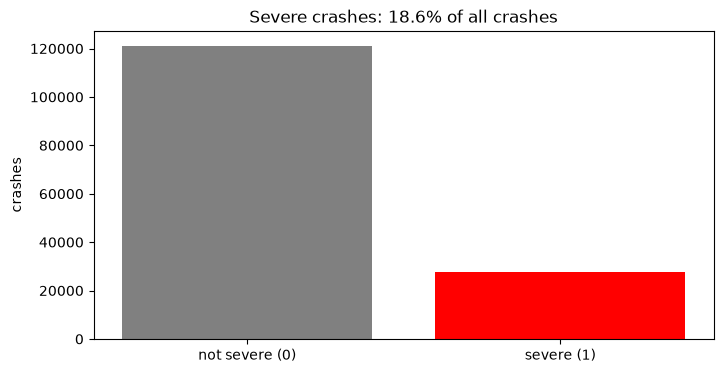

In [14]:
# 3.1 คำตอบ: รุนแรงกี่ % ของเหตุทั้งหมด
overall_percent = clean["severe"].mean() * 100
severe_counts = clean["severe"].value_counts().sort_index()

plt.bar(["not severe (0)", "severe (1)"], severe_counts.values, color=["grey", "red"])
plt.title("Severe crashes: " + str(round(overall_percent, 1)) + "% of all crashes")
plt.ylabel("crashes")
plt.show()

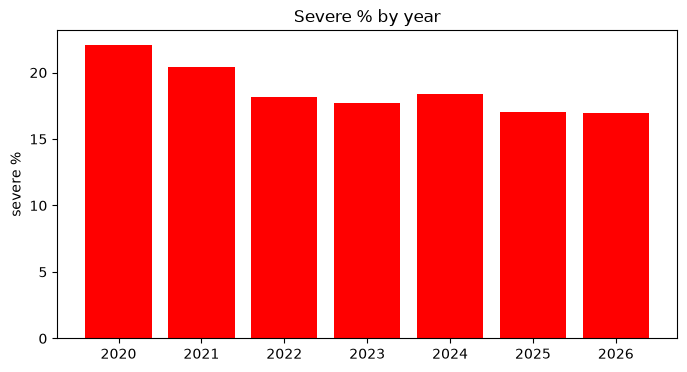

year
2020    22.1
2021    20.4
2022    18.2
2023    17.7
2024    18.4
2025    17.0
2026    16.9
Name: severe, dtype: float64


In [15]:
# 3.2 คำตอบ: % รุนแรงของแต่ละปี
percent_by_year = clean.groupby("year")["severe"].mean() * 100

plt.bar(percent_by_year.index, percent_by_year.values, color="red")
plt.title("Severe % by year")
plt.ylabel("severe %")
plt.show()
print(percent_by_year.round(1))

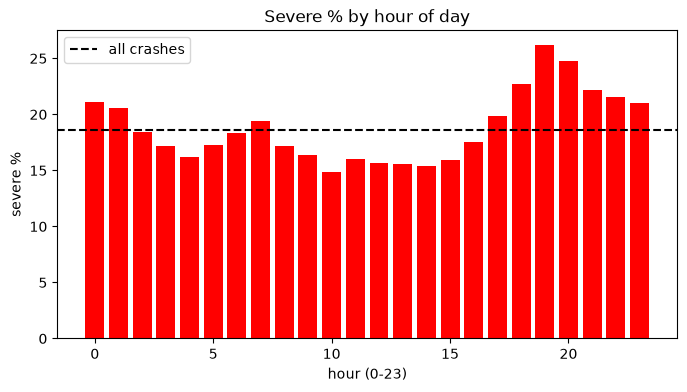

In [16]:
# 3.3 เวลา: % รุนแรงของแต่ละชั่วโมง
percent_by_hour = clean.groupby("hour")["severe"].mean() * 100

plt.bar(percent_by_hour.index, percent_by_hour.values, color="red")
plt.axhline(overall_percent, color="black", linestyle="--", label="all crashes")
plt.title("Severe % by hour of day")
plt.xlabel("hour (0-23)")
plt.ylabel("severe %")
plt.legend()
plt.show()

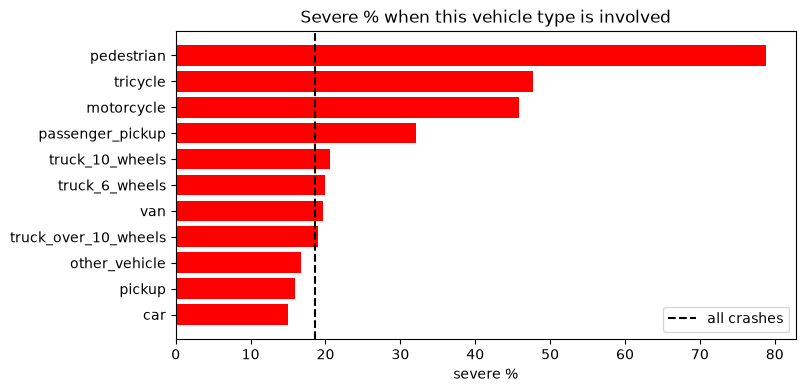

,vehicle,crashes,severe_percent
10,pedestrian,1537,78.9
1,tricycle,1041,47.6
0,motorcycle,32102,45.9
4,passenger_pickup,843,32.1
7,truck_10_wheels,6516,20.7
6,truck_6_wheels,8600,19.9
3,van,3548,19.7
8,truck_over_10_wheels,16655,19.0
9,other_vehicle,9504,16.7
5,pickup,69352,15.9


In [17]:
# 3.4 ประเภทรถ: ถ้ามีรถประเภทนี้อยู่ในเหตุ รุนแรงกี่ %
rows = []
for vehicle in vehicle_types:
    involved = clean[clean[vehicle] > 0]
    rows.append({"vehicle": vehicle, "crashes": len(involved), "severe_percent": involved["severe"].mean() * 100})

vehicle_table = pd.DataFrame(rows).sort_values("severe_percent")

plt.barh(vehicle_table["vehicle"], vehicle_table["severe_percent"], color="red")
plt.axvline(overall_percent, color="black", linestyle="--", label="all crashes")
plt.title("Severe % when this vehicle type is involved")
plt.xlabel("severe %")
plt.legend()
plt.show()
vehicle_table.sort_values("severe_percent", ascending=False).round(1)

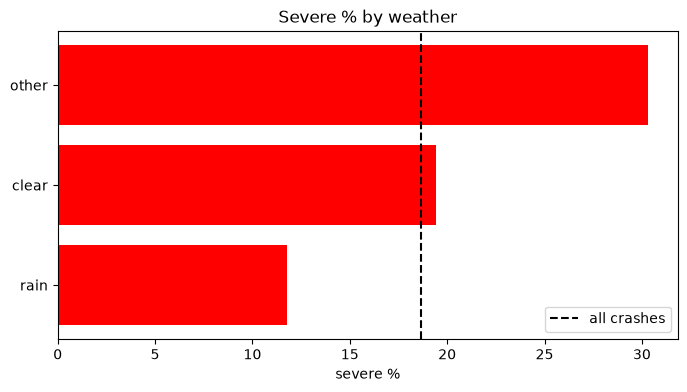

,crashes,severe_rate
weather,,
rain,18223,0.118
clear,128818,0.194
other,1949,0.303


In [18]:
# 3.5 อากาศ: % รุนแรงของแต่ละสภาพอากาศ
weather_table = clean.groupby("weather")["severe"].agg(["count", "mean"])
weather_table.columns = ["crashes", "severe_rate"]
weather_table = weather_table.sort_values("severe_rate")

plt.barh(weather_table.index, weather_table["severe_rate"] * 100, color="red")
plt.axvline(overall_percent, color="black", linestyle="--", label="all crashes")
plt.title("Severe % by weather")
plt.xlabel("severe %")
plt.legend()
plt.show()
weather_table.round(3)

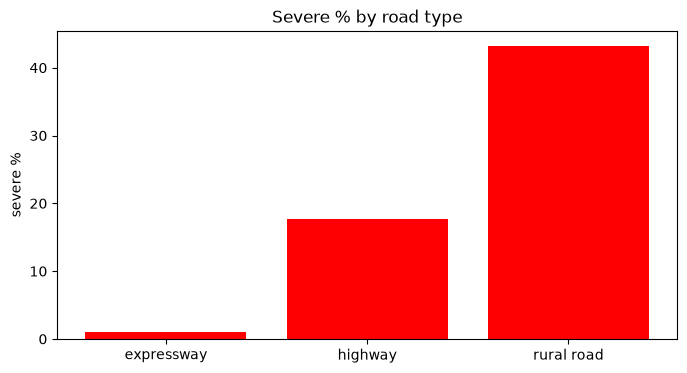

,crashes,severe_rate
road_type,,
expressway,1965,0.010
highway,140190,0.177
rural road,6835,0.433


In [19]:
# 3.6 เส้นถนน: % รุนแรงของแต่ละประเภทถนน
road_type_table = clean.groupby("road_type")["severe"].agg(["count", "mean"])
road_type_table.columns = ["crashes", "severe_rate"]

plt.bar(road_type_table.index, road_type_table["severe_rate"] * 100, color="red")
plt.title("Severe % by road type")
plt.ylabel("severe %")
plt.show()
road_type_table.round(3)

ช่วงถนนที่มีเหตุตั้งแต่ 30 ครั้ง: 1098 จาก 14223 ช่วง


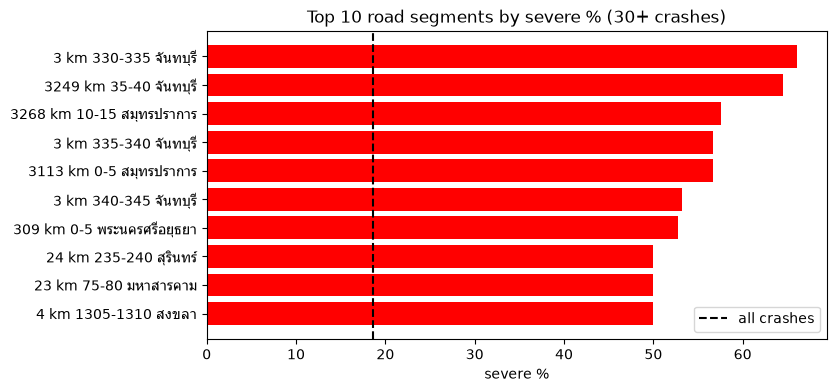

,crashes,severe_rate,road_name,province
road_segment,,,,
3 km 330-335 จันทบุรี,59,0.661,โพธิ์ทอง - บ้านพลิ้ว,จันทบุรี
3249 km 35-40 จันทบุรี,31,0.645,เขาไร่ยา - แพร่งขาหยั่ง,จันทบุรี
3268 km 10-15 สมุทรปราการ,33,0.576,บางพลี - บางบ่อ,สมุทรปราการ
3 km 335-340 จันทบุรี,67,0.567,โพธิ์ทอง - บ้านพลิ้ว,จันทบุรี
3113 km 0-5 สมุทรปราการ,30,0.567,สำโรง - สะพานภูมิพล,สมุทรปราการ
3 km 340-345 จันทบุรี,62,0.532,โพธิ์ทอง - บ้านพลิ้ว,จันทบุรี
309 km 0-5 พระนครศรีอยุธยา,55,0.527,วังน้อย - ทางแยกต่างระดับอยุธยา,พระนครศรีอยุธยา
24 km 235-240 สุรินทร์,50,0.500,กระเทียม - ห้วยสำราญ,สุรินทร์
23 km 75-80 มหาสารคาม,36,0.500,หนองจิก - ห้วยแอ่ง,มหาสารคาม


In [20]:
# 3.7 เส้นถนน: ช่วงถนน 5 กม. ที่ถ้าเกิดเหตุแล้วรุนแรงบ่อยที่สุด 10 อันดับ
min_segment_crashes = 30    # ช่วงที่มีเหตุน้อยกว่านี้ % จะแกว่ง จึงไม่จัดอันดับ

segment_table = clean.groupby("road_segment")["severe"].agg(["count", "mean"])
segment_table.columns = ["crashes", "severe_rate"]
segment_table["road_name"] = clean.groupby("road_segment")["road_name"].first()
segment_table["province"] = clean.groupby("road_segment")["province"].first()

busy_segments = segment_table[segment_table["crashes"] >= min_segment_crashes]
top_segments = busy_segments.sort_values("severe_rate", ascending=False).head(10)
print("ช่วงถนนที่มีเหตุตั้งแต่", min_segment_crashes, "ครั้ง:", len(busy_segments), "จาก", len(segment_table), "ช่วง")

plt.barh(top_segments.index, top_segments["severe_rate"] * 100, color="red")
plt.axvline(overall_percent, color="black", linestyle="--", label="all crashes")
plt.gca().invert_yaxis()
plt.title("Top 10 road segments by severe % (" + str(min_segment_crashes) + "+ crashes)")
plt.xlabel("severe %")
plt.legend()
plt.show()
top_segments.round(3)

เหตุปี 2024-2026 ที่อยู่บนช่วงถนนที่มีประวัติพอ: 40425 จาก 65472


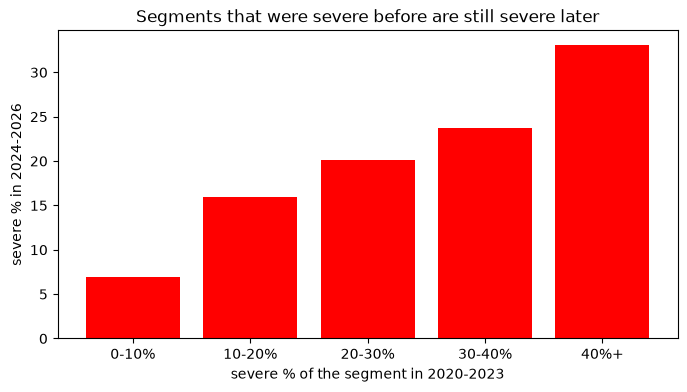

,future_crashes,future_severe_rate
past_band,,
0-10%,19450,0.070
10-20%,9074,0.160
20-30%,6188,0.202
30-40%,3505,0.238
40%+,2208,0.331


In [21]:
# 3.8 เส้นถนน: ช่วงถนนที่เคยรุนแรงในอดีต (2020-2023) ยังรุนแรงในปีหลัง (2024-2026) ไหม
min_past_crashes = 10       # ใช้เฉพาะช่วงที่มีเหตุในอดีตพอให้นับ

past = clean[clean["year"] <= 2023]
future = clean[clean["year"] >= 2024].copy()

past_table = past.groupby("road_segment")["severe"].agg(["count", "mean"])
past_table.columns = ["past_crashes", "past_severe_rate"]
past_table = past_table[past_table["past_crashes"] >= min_past_crashes]


def to_band(rate):
    if rate < 0.10:
        return "0-10%"
    if rate < 0.20:
        return "10-20%"
    if rate < 0.30:
        return "20-30%"
    if rate < 0.40:
        return "30-40%"
    return "40%+"


past_table["past_band"] = past_table["past_severe_rate"].apply(to_band)
future["past_band"] = future["road_segment"].map(past_table["past_band"])

band_table = future.groupby("past_band")["severe"].agg(["count", "mean"])
band_table.columns = ["future_crashes", "future_severe_rate"]
print("เหตุปี 2024-2026 ที่อยู่บนช่วงถนนที่มีประวัติพอ:", band_table["future_crashes"].sum(), "จาก", len(future))

plt.bar(band_table.index, band_table["future_severe_rate"] * 100, color="red")
plt.title("Segments that were severe before are still severe later")
plt.xlabel("severe % of the segment in 2020-2023")
plt.ylabel("severe % in 2024-2026")
plt.show()
band_table.round(3)

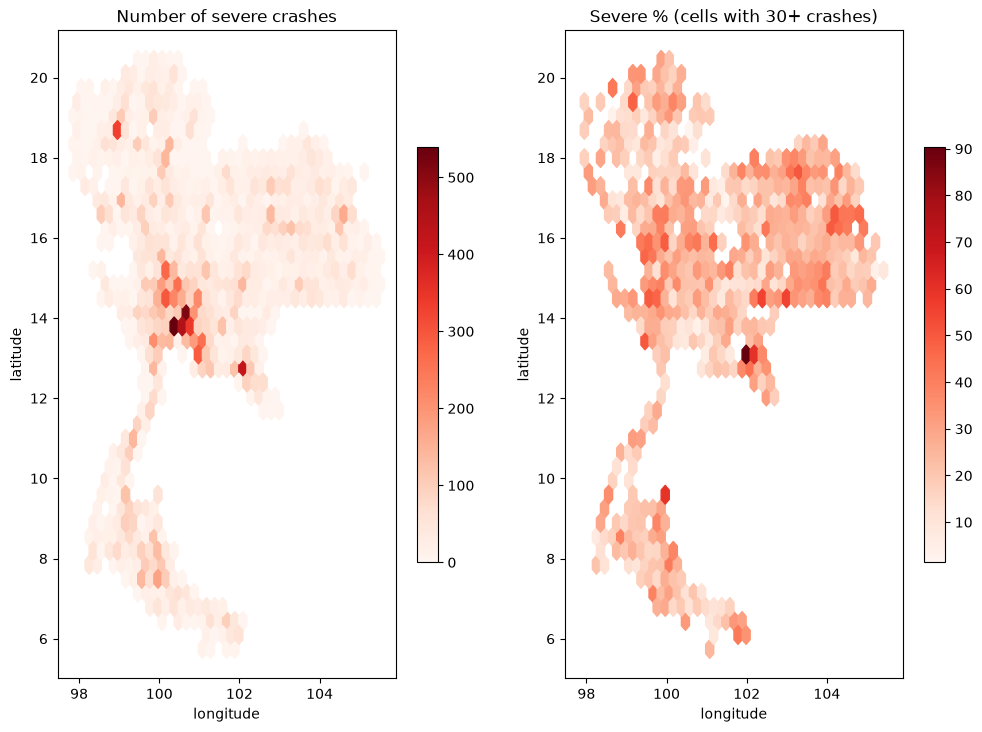

In [22]:
# 3.9 แผนที่: แบ่งเป็นช่องหกเหลี่ยม 38 ช่องตามแนวกว้าง แล้วระบายสีตามเหตุรุนแรง
grid_size = 38
min_cell_crashes = 30       # ช่องที่มีเหตุน้อยกว่านี้ % จะแกว่ง จึงไม่แสดงในแผนที่ขวา

map_data = clean.dropna(subset=["latitude", "longitude"])
fig, axes = plt.subplots(1, 2, figsize=(12, 9))

left = axes[0].hexbin(map_data["longitude"], map_data["latitude"], C=map_data["severe"],
                      reduce_C_function=np.sum, gridsize=grid_size, mincnt=1, cmap="Reds")
axes[0].set_title("Number of severe crashes")
fig.colorbar(left, ax=axes[0], shrink=0.6)

right = axes[1].hexbin(map_data["longitude"], map_data["latitude"], C=map_data["severe"] * 100,
                       reduce_C_function=np.mean, gridsize=grid_size, mincnt=min_cell_crashes, cmap="Reds")
axes[1].set_title("Severe % (cells with " + str(min_cell_crashes) + "+ crashes)")
fig.colorbar(right, ax=axes[1], shrink=0.6)

for ax in axes:
    ax.set_xlabel("longitude")
    ax.set_ylabel("latitude")
    ax.set_aspect("equal")
plt.show()

### สรุปจากกราฟ
- **ข้อมูลหลังคลีน:** 148,990 เหตุ บนถนน 2,977 เส้น แบ่งเป็น 14,223 ช่วง (ช่วงละ 5 กม. แยกตามจังหวัด)
- **คำตอบ:** รุนแรง 18.6% และลดลงจาก 22.1% (2020) เหลือ 16.9% (2026)
- **เวลา:** กลางคืนรุนแรงกว่า สูงสุดตอน 19 นาฬิกา (26.2%) ต่ำสุดตอน 10 นาฬิกา (14.8%)
- **ประเภทรถ:** มีคนเดินเท้า 78.9% สามล้อ 47.6% จักรยานยนต์ 45.9% ส่วนรถยนต์ 14.9%
- **อากาศ:** ฝนตกรุนแรงน้อยกว่าอากาศแจ่มใส (11.8% กับ 19.4%)
- **เส้นถนน:** ช่วงที่เคยรุนแรงเกิน 40% ในปี 2020-2023 ยังรุนแรง 33.1% ในปี 2024-2026 ส่วนช่วงที่เคยต่ำกว่า 10% เหลือ 7.0% แปลว่าเส้นถนน + กม. ใช้ทำนายได้
- **ระวัง:** ทางพิเศษรุนแรง 1.0% แต่ทางหลวงชนบท 43.3% ส่วนหนึ่งอาจมาจากวิธีบันทึกที่ต่างกัน ไม่ใช่ความอันตรายของถนนอย่างเดียว

## 4. สร้าง X
X = เส้นถนน (ประวัติของช่วงถนน) + ประเภทรถ + เวลา + อากาศ

In [23]:
# 4.1 ประวัติของช่วงถนน = % รุนแรงในอดีตของช่วงถนนนั้น
# ต้องใช้เฉพาะปีก่อนหน้า ถ้าใช้ปีเดียวกันด้วย เท่ากับให้โมเดลดูเฉลย
min_history = 10        # ช่วงถนนต้องมีเหตุในอดีตอย่างน้อย 10 ครั้ง ถึงจะเชื่อ % ของช่วงนั้น


def road_history(past, rows):
    segment_rate = rows["road_segment"].map(past.groupby("road_segment")["severe"].mean())
    segment_count = rows["road_segment"].map(past.groupby("road_segment")["severe"].count()).fillna(0)
    road_rate = rows["road_code"].map(past.groupby("road_code")["severe"].mean())
    road_count = rows["road_code"].map(past.groupby("road_code")["severe"].count()).fillna(0)

    history = pd.Series(past["severe"].mean(), index=rows.index)                        # เริ่มจาก % ของทั้งประเทศ
    history[road_count >= min_history] = road_rate[road_count >= min_history]             # ถ้าทั้งเส้นมีเหตุพอ ใช้ % ของทั้งเส้น
    history[segment_count >= min_history] = segment_rate[segment_count >= min_history]    # ถ้าช่วงนี้มีเหตุพอ ใช้ % ของช่วงนี้
    return history


clean["road_history"] = np.nan
for year in [2021, 2022, 2023, 2024, 2025, 2026]:      # ปี 2020 ไม่มีปีก่อนหน้า จึงใช้เป็นประวัติอย่างเดียว
    past = clean[clean["year"] < year]
    this_year = clean["year"] == year
    clean.loc[this_year, "road_history"] = road_history(past, clean[this_year])

clean[["year", "road_segment", "road_history", "severe"]].tail(3)

,year,road_segment,road_history,severe
148987,2026,E002S016|I km 5-10 กรุงเทพมหานคร,0.000000,0
148988,2026,7 km 10-15 กรุงเทพมหานคร,0.011952,0
148989,2026,7 km 25-30 สมุทรปราการ,0.009576,0


In [24]:
# 4.2 ปัจจัยอื่น: ทุกตัวเป็น 0/1 (มี = 1, ไม่มี = 0)
def make_features(data):
    x = pd.DataFrame(index=data.index)

    # เส้นถนน
    x["road_history"] = data["road_history"]
    x["rural_road"] = (data["road_type"] == "rural road").astype(int)
    x["expressway"] = (data["road_type"] == "expressway").astype(int)

    # ประเภทรถที่อยู่ในเหตุ
    for vehicle in vehicle_types:
        x[vehicle] = (data[vehicle] > 0).astype(int)
    x["two_vehicles"] = (data["vehicle_count"] == 2).astype(int)
    x["three_plus_vehicles"] = (data["vehicle_count"] >= 3).astype(int)

    # เวลา
    month = data["date"].dt.month
    day = data["date"].dt.day
    new_year = ((month == 12) & (day >= 27)) | ((month == 1) & (day <= 4))
    songkran = (month == 4) & (day >= 10) & (day <= 17)
    x["night"] = ((data["hour"] >= 19) | (data["hour"] <= 4)).astype(int)
    x["weekend"] = (data["date"].dt.day_of_week >= 5).astype(int)
    x["festival"] = (new_year | songkran).astype(int)

    # อากาศ
    x["rain"] = (data["weather"] == "rain").astype(int)
    return x


x_all = make_features(clean)
y_all = clean["severe"]
feature_columns = list(x_all.columns)
print("X มี", len(feature_columns), "คอลัมน์:", feature_columns)

X มี 20 คอลัมน์: ['road_history', 'rural_road', 'expressway', 'motorcycle', 'tricycle', 'car', 'van', 'passenger_pickup', 'pickup', 'truck_6_wheels', 'truck_10_wheels', 'truck_over_10_wheels', 'other_vehicle', 'pedestrian', 'two_vehicles', 'three_plus_vehicles', 'night', 'weekend', 'festival', 'rain']


In [25]:
# 4.3 แบ่งตามปี: เรียนจากอดีต แล้วทายอนาคต
clean["split"] = "history only"
clean.loc[(clean["year"] >= 2021) & (clean["year"] <= 2023), "split"] = "train"
clean.loc[clean["year"] == 2024, "split"] = "validation"
clean.loc[clean["year"] >= 2025, "split"] = "test"

x_train = x_all[clean["split"] == "train"]
y_train = y_all[clean["split"] == "train"]
x_validation = x_all[clean["split"] == "validation"]
y_validation = y_all[clean["split"] == "validation"]
x_test = x_all[clean["split"] == "test"]
y_test = y_all[clean["split"] == "test"]

# บันทึก X และ y
features = x_all.copy()
features["year"] = clean["year"]
features["split"] = clean["split"]
features["severe"] = y_all
features.to_csv(output_dir + "features/road_features.csv", index=False, encoding="utf-8-sig")

split_table = clean.groupby("split")["severe"].agg(["count", "mean"])
split_table.columns = ["crashes", "severe_rate"]
split_table.round(3)

,crashes,severe_rate
split,,
history only,21135,0.221
test,41770,0.170
train,62383,0.187
validation,23702,0.184


## 5. เลือกโมเดล
ฝึกด้วย train (2021-2023) แล้ววัดด้วย validation (2024) โมเดลให้ % ถ้าได้ตั้งแต่ 30% ขึ้นไป นับว่าทายว่ารุนแรง

In [26]:
threshold = 0.30        # เหตุรุนแรงมีแค่ราว 1 ใน 5 จึงใช้เกณฑ์ต่ำกว่า 50%


def predict_with_threshold(model, x):
    percent = model.predict_proba(x)[:, 1]      # คอลัมน์ที่ 1 = โอกาสรุนแรง (0.0 ถึง 1.0)
    return (percent >= threshold).astype(int)


def evaluate(name, y_true, y_pred):
    matrix = confusion_matrix(y_true, y_pred, labels=[0, 1])    # [[TN, FP], [FN, TP]]
    tn = matrix[0, 0]
    fp = matrix[0, 1]
    fn = matrix[1, 0]
    tp = matrix[1, 1]

    precision = 0
    if tp + fp > 0:
        precision = tp / (tp + fp)
    recall = tp / (tp + fn)
    f1 = 0
    if precision + recall > 0:
        f1 = 2 * precision * recall / (precision + recall)

    return {"model": name, "TN": tn, "FP": fp, "FN": fn, "TP": tp,
            "accuracy": (tp + tn) / (tp + tn + fp + fn), "precision": precision, "recall": recall, "F1": f1}

In [27]:
# 5.1 ฝึก 3 โมเดล แล้วเทียบกับวิธีง่าย ๆ (baseline) ที่โมเดลต้องชนะ
models = {
    "Logistic Regression": LogisticRegression(max_iter=1000),
    "Decision Tree": DecisionTreeClassifier(max_depth=6, min_samples_leaf=50, random_state=42),
    "Random Forest": RandomForestClassifier(n_estimators=100, min_samples_leaf=20, random_state=42),
}

results = []
results.append(evaluate("baseline: all not severe", y_validation, np.zeros(len(y_validation), dtype=int)))
results.append(evaluate("baseline: has motorcycle", y_validation, x_validation["motorcycle"]))
results.append(evaluate("baseline: road history >= 30%", y_validation, (x_validation["road_history"] >= threshold).astype(int)))

for name in models:
    model = models[name]
    model.fit(x_train, y_train)
    results.append(evaluate(name, y_validation, predict_with_threshold(model, x_validation)))

validation_table = pd.DataFrame(results)
validation_table.round(3)

,model,TN,FP,FN,TP,accuracy,precision,recall,F1
0,baseline: all not severe,19345,0,4357,0,0.816,0.000,0.000,0.000
1,baseline: has motorcycle,16573,2772,2130,2227,0.793,0.445,0.511,0.476
2,baseline: road history >= 30%,17181,2164,3361,996,0.767,0.315,0.229,0.265
3,Logistic Regression,16953,2392,2024,2333,0.814,0.494,0.535,0.514
4,Decision Tree,17367,1978,2111,2246,0.827,0.532,0.515,0.523
5,Random Forest,17006,2339,1849,2508,0.823,0.517,0.576,0.545


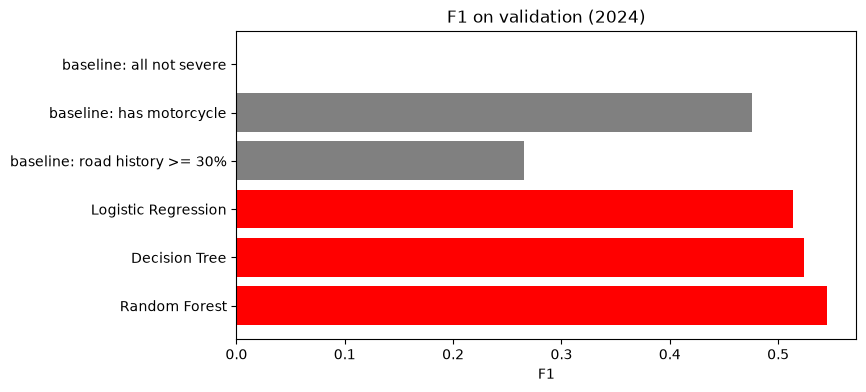

โมเดลที่ดีที่สุด: Random Forest


In [28]:
colors = []
for name in validation_table["model"]:
    if name.startswith("baseline"):
        colors.append("grey")
    else:
        colors.append("red")

plt.barh(validation_table["model"], validation_table["F1"], color=colors)
plt.gca().invert_yaxis()
plt.title("F1 on validation (2024)")
plt.xlabel("F1")
plt.show()

# เลือกโมเดลที่ F1 สูงที่สุด (ไม่นับ baseline)
model_rows = validation_table[~validation_table["model"].str.startswith("baseline")]
best_name = model_rows.sort_values("F1", ascending=False)["model"].iloc[0]
print("โมเดลที่ดีที่สุด:", best_name)

In [29]:
# 5.2 เส้นถนนช่วยจริงไหม: ตัด X ออกทีละกลุ่ม แล้วดูว่า F1 ตกเท่าไร (ใช้ Random Forest)
road_columns = ["road_history", "rural_road", "expressway"]
vehicle_columns = vehicle_types + ["two_vehicles", "three_plus_vehicles"]


def remove_columns(columns, to_remove):
    kept = []
    for column in columns:
        if column not in to_remove:
            kept.append(column)
    return kept


feature_sets = {
    "all X": feature_columns,
    "without road": remove_columns(feature_columns, road_columns),
    "without vehicle types": remove_columns(feature_columns, vehicle_columns),
}

ablation_rows = []
for name in feature_sets:
    columns = feature_sets[name]
    model = RandomForestClassifier(n_estimators=100, min_samples_leaf=20, random_state=42)
    model.fit(x_train[columns], y_train)
    ablation_rows.append(evaluate(name, y_validation, predict_with_threshold(model, x_validation[columns])))

pd.DataFrame(ablation_rows).round(3)

,model,TN,FP,FN,TP,accuracy,precision,recall,F1
0,all X,17006,2339,1849,2508,0.823,0.517,0.576,0.545
1,without road,16463,2882,1869,2488,0.800,0.463,0.571,0.512
2,without vehicle types,17567,1778,3463,894,0.779,0.335,0.205,0.254


## 6. วัดผลครั้งสุดท้าย (test)
ฝึกโมเดลที่ชนะใหม่ด้วยปี 2021-2024 แล้วทายปี 2025-2026 ที่โมเดลไม่เคยเห็น

In [30]:
x_train_validation = pd.concat([x_train, x_validation])
y_train_validation = pd.concat([y_train, y_validation])

final_model = models[best_name]
final_model.fit(x_train_validation, y_train_validation)
test_pred = predict_with_threshold(final_model, x_test)

test_results = []
test_results.append(evaluate("baseline: all not severe", y_test, np.zeros(len(y_test), dtype=int)))
test_results.append(evaluate("baseline: has motorcycle", y_test, x_test["motorcycle"]))
test_results.append(evaluate("baseline: road history >= 30%", y_test, (x_test["road_history"] >= threshold).astype(int)))
test_results.append(evaluate(best_name, y_test, test_pred))

test_table = pd.DataFrame(test_results)
test_table.to_csv(output_dir + "results/test_scores.csv", index=False, encoding="utf-8-sig")
test_table.round(3)

,model,TN,FP,FN,TP,accuracy,precision,recall,F1
0,baseline: all not severe,34676,0,7094,0,0.830,0.000,0.000,0.000
1,baseline: has motorcycle,30210,4466,3260,3834,0.815,0.462,0.540,0.498
2,baseline: road history >= 30%,30134,4542,5132,1962,0.768,0.302,0.277,0.289
3,Random Forest,30894,3782,2816,4278,0.842,0.531,0.603,0.565


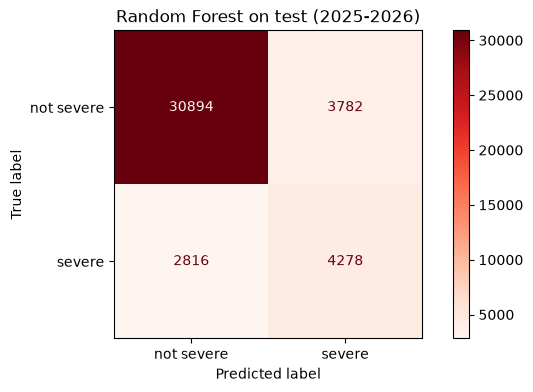

              precision    recall  f1-score   support

  not severe       0.92      0.89      0.90     34676
      severe       0.53      0.60      0.56      7094

    accuracy                           0.84     41770
   macro avg       0.72      0.75      0.73     41770
weighted avg       0.85      0.84      0.85     41770



In [31]:
ConfusionMatrixDisplay.from_predictions(y_test, test_pred, display_labels=["not severe", "severe"], cmap="Reds", values_format="d")
plt.title(best_name + " on test (2025-2026)")
plt.show()

print(classification_report(y_test, test_pred, target_names=["not severe", "severe"]))

## 7. ปัจจัยไหนส่งผลที่สุด
ลองเปลี่ยนค่าของปัจจัยทีละตัวให้กับทุกเหตุในชุด test แล้วดูว่า % ที่โมเดลทายเปลี่ยนไปเท่าไร

In [32]:
# 7.1 ปัจจัยแบบ 0/1: ให้ทุกเหตุ "ไม่มี" ปัจจัยนี้ เทียบกับ "มี" ปัจจัยนี้
def average_percent(model, x, changes):
    x_changed = x.copy()
    for column in changes:
        x_changed[column] = changes[column]
    return model.predict_proba(x_changed)[:, 1].mean() * 100


# ปัจจัยที่เป็นได้ทีละแบบ ตอนลองตัวหนึ่ง ต้องปิดอีกตัว
partner = {
    "two_vehicles": "three_plus_vehicles",
    "three_plus_vehicles": "two_vehicles",
    "rural_road": "expressway",
    "expressway": "rural_road",
}

effect_rows = []
for factor in feature_columns:
    if factor == "road_history":
        continue                                # ไม่ใช่ 0/1 จึงดูแยกในข้อ 7.2
    changes_without = {factor: 0}
    changes_with = {factor: 1}
    if factor in partner:
        changes_without[partner[factor]] = 0
        changes_with[partner[factor]] = 0
    percent_without = average_percent(final_model, x_test, changes_without)
    percent_with = average_percent(final_model, x_test, changes_with)
    effect_rows.append({"factor": factor, "percent_without": percent_without, "percent_with": percent_with,
                        "change": percent_with - percent_without})

effect_table = pd.DataFrame(effect_rows).sort_values("change")
effect_table.to_csv(output_dir + "results/factor_effects.csv", index=False, encoding="utf-8-sig")

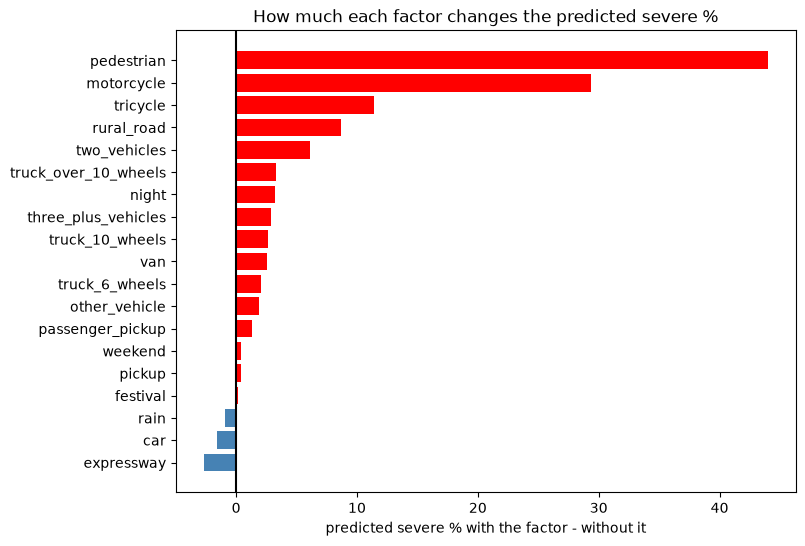

,factor,percent_without,percent_with,change
12,pedestrian,16.7,60.7,44.0
2,motorcycle,12.2,41.5,29.3
3,tricycle,17.2,28.5,11.4
0,rural_road,17.2,25.9,8.7
13,two_vehicles,15.9,22.0,6.1
10,truck_over_10_wheels,17.0,20.3,3.3
15,night,16.3,19.4,3.2
14,three_plus_vehicles,15.9,18.8,2.9
9,truck_10_wheels,17.2,19.8,2.6
5,van,17.2,19.8,2.6


In [33]:
colors = []
for change in effect_table["change"]:
    if change > 0:
        colors.append("red")
    else:
        colors.append("steelblue")

plt.figure(figsize=(8, 6))
plt.barh(effect_table["factor"], effect_table["change"], color=colors)
plt.axvline(0, color="black")
plt.title("How much each factor changes the predicted severe %")
plt.xlabel("predicted severe % with the factor - without it")
plt.show()

effect_table.sort_values("change", ascending=False).round(1)

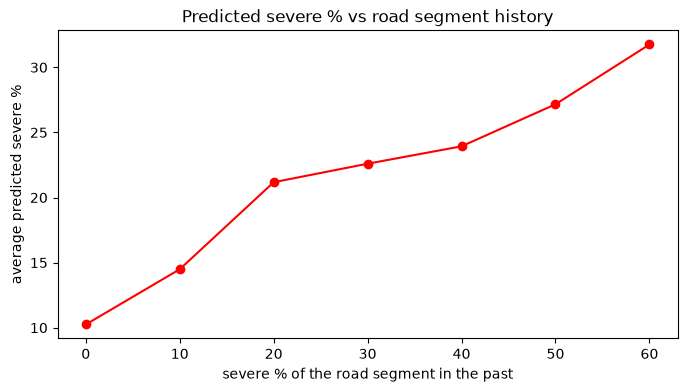

,road_history_percent,predicted_percent
0,0.0,10.2
1,10.0,14.5
2,20.0,21.2
3,30.0,22.6
4,40.0,23.9
5,50.0,27.2
6,60.0,31.8


In [34]:
# 7.2 ประวัติช่วงถนน: ลองให้ทุกเหตุมีประวัติ 0%, 10%, ..., 60% แล้วดู % ที่โมเดลทาย
history_values = [0.0, 0.1, 0.2, 0.3, 0.4, 0.5, 0.6]
curve = []
for value in history_values:
    curve.append(average_percent(final_model, x_test, {"road_history": value}))

plt.plot(np.array(history_values) * 100, curve, marker="o", color="red")
plt.title("Predicted severe % vs road segment history")
plt.xlabel("severe % of the road segment in the past")
plt.ylabel("average predicted severe %")
plt.show()

pd.DataFrame({"road_history_percent": np.array(history_values) * 100, "predicted_percent": curve}).round(1)

## 8. ลองใช้: ปักจุดบนแผนที่ → % รุนแรง
ปักจุด → หาว่าเป็นถนนเส้นไหน กม. เท่าไร → ใส่สถานการณ์ → โมเดลบอก %

In [35]:
km_per_degree = 111     # 1 องศาละติจูด/ลองจิจูด ประมาณ 111 กม.
max_distance_km = 2     # ถ้าจุดที่ปักห่างจากเหตุในข้อมูลเกิน 2 กม. ถือว่าไม่รู้จักถนนตรงนั้น


def predict_severity(latitude, longitude, involved, night, rain):
    # 1) หาเหตุในอดีตที่ใกล้จุดที่ปักที่สุด เพื่อรู้ว่าเป็นถนนเส้นไหน กม. เท่าไร
    distance_km = np.sqrt(((clean["latitude"] - latitude) * km_per_degree) ** 2
                          + ((clean["longitude"] - longitude) * km_per_degree) ** 2)
    if distance_km.min() > max_distance_km:
        return {"road_segment": "no road nearby", "severe_percent": np.nan}
    nearest = clean.loc[[distance_km.idxmin()]]

    # 2) สร้าง X หนึ่งแถว: เริ่มจาก 0 ทุกช่อง แล้วเติมตามสถานการณ์ (วันธรรมดา นอกเทศกาล)
    row = pd.DataFrame(0, index=nearest.index, columns=feature_columns)
    row["road_history"] = road_history(clean, nearest)          # ใช้ประวัติทุกปีที่มี
    row["rural_road"] = int(nearest["road_type"].iloc[0] == "rural road")
    row["expressway"] = int(nearest["road_type"].iloc[0] == "expressway")

    vehicle_count = 0
    for item in involved:
        row[item] = 1
        if item != "pedestrian":
            vehicle_count = vehicle_count + 1
    if vehicle_count == 2:
        row["two_vehicles"] = 1
    if vehicle_count >= 3:
        row["three_plus_vehicles"] = 1
    row["night"] = night
    row["rain"] = rain

    # 3) ให้โมเดลทาย %
    percent = final_model.predict_proba(row)[0, 1] * 100
    return {"road_segment": nearest["road_segment"].iloc[0],
            "road_name": nearest["road_name"].iloc[0],
            "province": nearest["province"].iloc[0],
            "road_history_percent": row["road_history"].iloc[0] * 100,
            "severe_percent": percent}

In [36]:
# 8.1 ตัวอย่าง: ปักจุด 2 ที่ ลอง 2 สถานการณ์
examples = [
    {"pin": "Chanthaburi", "latitude": 12.6217, "longitude": 102.1476, "scenario": "motorcycle, night",
     "involved": ["motorcycle"], "night": 1, "rain": 0},
    {"pin": "Chanthaburi", "latitude": 12.6217, "longitude": 102.1476, "scenario": "car + pickup, day",
     "involved": ["car", "pickup"], "night": 0, "rain": 0},
    {"pin": "Bangkok", "latitude": 13.7831, "longitude": 100.4531, "scenario": "motorcycle, night",
     "involved": ["motorcycle"], "night": 1, "rain": 0},
    {"pin": "Bangkok", "latitude": 13.7831, "longitude": 100.4531, "scenario": "car + pickup, day",
     "involved": ["car", "pickup"], "night": 0, "rain": 0},
]

example_rows = []
for example in examples:
    answer = predict_severity(example["latitude"], example["longitude"], example["involved"], example["night"], example["rain"])
    answer["pin"] = example["pin"]
    answer["scenario"] = example["scenario"]
    example_rows.append(answer)

example_table = pd.DataFrame(example_rows)
example_table[["pin", "road_segment", "road_name", "road_history_percent", "scenario", "severe_percent"]].round(1)

,pin,road_segment,road_name,road_history_percent,scenario,severe_percent
0,Chanthaburi,3 km 330-335 จันทบุรี,โพธิ์ทอง - บ้านพลิ้ว,66.1,"motorcycle, night",69.8
1,Chanthaburi,3 km 330-335 จันทบุรี,โพธิ์ทอง - บ้านพลิ้ว,66.1,"car + pickup, day",35.9
2,Bangkok,338 km 0-5 กรุงเทพมหานคร,อรุณอมรินทร์ - พุทธมณฑลสาย 4,6.5,"motorcycle, night",34.8
3,Bangkok,338 km 0-5 กรุงเทพมหานคร,อรุณอมรินทร์ - พุทธมณฑลสาย 4,6.5,"car + pickup, day",3.4


## 9. สรุป

| หัวข้อ | คำตอบ |
|---|---|
| **Input (X)** | เส้นถนน (ประวัติของช่วงถนน 5 กม. + ประเภทถนน), ประเภทรถ, เวลา, อากาศ รวม 20 คอลัมน์ |
| **Output** | % ที่อุบัติเหตุจะรุนแรง (มีผู้เสียชีวิตหรือบาดเจ็บสาหัส) |
| **Model** | Random Forest ได้ F1 บน validation สูงสุด (0.545) เทียบกับ Decision Tree 0.523 และ Logistic Regression 0.514 |
| **ผลบน test (2025-2026)** | Accuracy 84.2%, Precision 53.1%, Recall 60.3%, F1 0.565 ชนะ baseline "มีจักรยานยนต์" (0.498) |

- **เส้นถนนช่วยจริง:** ตัดเส้นถนนออก F1 ตกจาก 0.545 เหลือ 0.512
- **ต้องรู้ประเภทรถ:** ถ้าไม่มีประเภทรถ F1 เหลือ 0.254 แผนที่จึงต้องให้คนใช้เลือกว่ามีรถอะไรเกี่ยวข้อง
- **ปัจจัยที่ดัน % มากที่สุด:** มีคนเดินเท้า +44.0 จุด, จักรยานยนต์ +29.3, สามล้อ +11.4, ทางหลวงชนบท +8.7, รถ 2 คัน +6.1 ส่วนประวัติช่วงถนนจาก 0% ถึง 60% ดัน % จาก 10.2% เป็น 31.8%
- **ตัวอย่าง:** จักรยานยนต์ตอนกลางคืน บนถนน 3 ที่จันทบุรี ได้ 69.8% แต่บนถนน 338 ที่กรุงเทพ ได้ 34.8%
- **ข้อจำกัด:** โมเดลยังพลาดเหตุรุนแรง 40% (FN 2,816 จาก 7,094) / ผลเป็นความสัมพันธ์ ไม่ใช่การพิสูจน์สาเหตุ / ทางพิเศษกับทางหลวงชนบทบันทึกเหตุต่างกัน / ถ้าปักจุดห่างจากเหตุในข้อมูลเกิน 2 กม. จะทายไม่ได้